# Combining the probes

Runs every way of combining the Hindi and Marathi probes for each Marathi budget
in `config.yaml` (25 to 800 labelled sentences), with five seeds, at the main
setting (layer 7, first-piece). It follows the protocol in the readme. Scores
are on Marathi dev; the test split stays untouched.

In [1]:
import copy
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import numpy as np
import torch
import yaml
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd()
CONFIG = yaml.safe_load((ROOT / "config.yaml").read_text())
CACHE = ROOT / "data" / "cache"
samples = json.loads((CACHE / "samples.json").read_text())
LAYER, POOLING = CONFIG["main_setting"]["layer"], CONFIG["main_setting"]["pooling"]


class Split:
    """One split's cached features at the main setting, its labels (True = Nom) and its nouns by sentence."""

    def __init__(self, language: str, split: str):
        nouns = json.loads((CACHE / f"{language}_{split}_nouns.json").read_text())
        self.x = np.asarray(np.load(CACHE / f"{language}_{split}_{POOLING}.npy", mmap_mode="r")[LAYER])
        self.y = np.array([noun["label"] == "Nom" for noun in nouns])
        self.sentence = np.array([noun["sentence"] for noun in nouns])
        self.form = np.array([noun["form"] for noun in nouns])
        self.by_sentence = defaultdict(list)
        for k, noun in enumerate(nouns):
            self.by_sentence[noun["sentence"]].append(k)

    def rows(self, sentences) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Features, labels and sentence ids of the nouns in these sentences; a sentence listed twice is used twice."""
        keep = [k for s in sentences for k in self.by_sentence[s]]
        return self.x[keep], self.y[keep], self.sentence[keep]

    def replaced(self, x: np.ndarray | None = None, y: np.ndarray | None = None) -> "Split":
        """A copy with different features or labels, used by the controls."""
        out = copy.copy(self)
        out.x = self.x if x is None else x
        out.y = self.y if y is None else y
        return out


hindi, marathi, dev = Split("hi", "train"), Split("mr", "train"), Split("mr", "dev")
majority = max(dev.y.mean(), 1 - dev.y.mean())
print(f"layer {LAYER}, {POOLING}-piece; Marathi dev: {len(dev.y)} nouns, majority {majority:.3f}")

layer 7, first-piece; Marathi dev: 3308 nouns, majority 0.516


## Methods

With a budget of n labelled Marathi sentences:

Every probe chooses its regularisation strength (C) by 5-fold cross-validation
over its own training sentences, so no probe is held back by a setting that
suits a different amount of data.

- **Hindi probe:** trained on the seed's 800 Hindi sentences only.
- **Marathi probe:** trained on 80% of the n sentences, and again on all n.
- **Pooled:** one probe trained on the Hindi sentences plus all n Marathi sentences.
- **Weight blend:** the Hindi and Marathi (80%) probes, each scaled to length 1,
  mixed in one fixed proportion for every noun. The proportion and a shared
  scale and bias are learned on the other 20%.
- **Router:** the same, but the proportion depends on the noun through a gate
  learned on the 20%. How strongly the gate is held back (its penalty) is chosen
  by cross-validation over the 20%'s sentences; "no gate" is one of the choices,
  so the router can fall back to the weight blend.
- **Marathi + Marathi control:** the blend and the router again, with the Hindi
  probe swapped for a second Marathi probe trained on a resample of the same 80%.
  It uses no extra data, so it shows what combining two probes gives on its own.

The weight blend is exactly the router with a gate that ignores the noun, so any
difference between them comes from choosing per noun.

In [2]:
PENALTIES = [None, 1e4, 1e3, 1e2, 1e1, 1.0, 0.1, 0.01]
CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def probe(x: np.ndarray, y: np.ndarray, groups: np.ndarray) -> LogisticRegressionCV:
    """Train a probe, choosing C by 5-fold cross-validation that keeps each sentence's nouns together."""
    folds = list(GroupKFold(n_splits=5).split(x, y, groups))
    return LogisticRegressionCV(Cs=CS, cv=folds, scoring="neg_log_loss", max_iter=5000).fit(x, y)


def unit(model: LogisticRegression) -> np.ndarray:
    w = model.coef_[0]
    return w / np.linalg.norm(w)


def logits(mix, x, s_a, s_b) -> np.ndarray:
    """a·(g·s_a + (1 − g)·s_b) + b, with gate g = sigmoid(v·h + c)."""
    c, a, b, v = mix
    g = 1 / (1 + np.exp(-(x @ v + c)))
    return a * (g * s_a + (1 - g) * s_b) + b


def fit_mix(x, s_a, s_b, y, penalty=None, start=(0.0, 1.0, 0.0)):
    """Learn (c, a, b, v) of `logits` from two probes' scores s_a and s_b.

    With penalty None, v stays 0 and every noun gets the same mix (the weight
    blend); otherwise v is learned with an L2 penalty of that strength (the
    router). Like scikit-learn's C=1, the loss is the summed log loss plus a²/2.
    """
    x, s_a, s_b, y = (torch.as_tensor(t, dtype=torch.float64) for t in (x, s_a, s_b, y))
    c, a, b = (torch.tensor(float(t), dtype=torch.float64, requires_grad=True) for t in start)
    v = torch.zeros(x.shape[1], dtype=torch.float64, requires_grad=penalty is not None)
    optimiser = torch.optim.LBFGS([c, a, b] + ([v] if penalty is not None else []),
                                  max_iter=500, line_search_fn="strong_wolfe")

    def closure():
        optimiser.zero_grad()
        g = torch.sigmoid(x @ v + c)
        out = a * (g * s_a + (1 - g) * s_b) + b
        loss = torch.nn.functional.binary_cross_entropy_with_logits(out, y, reduction="sum") + a * a / 2
        if penalty is not None:
            loss = loss + penalty * (v @ v) / 2
        loss.backward()
        return loss

    optimiser.step(closure)
    return c.item(), a.item(), b.item(), v.detach().numpy()


def combine(w_a: np.ndarray, w_b: np.ndarray, marathi: Split, sentences: list[int]):
    """Fit the weight blend and the router of two length-1 probes on these Marathi sentences."""
    x, y, _ = marathi.rows(sentences)
    k = min(5, len(sentences))
    fold = np.concatenate([[i % k] * len(marathi.by_sentence[s]) for i, s in enumerate(sentences)])
    s_a, s_b = x @ w_a, x @ w_b
    blend = fit_mix(x, s_a, s_b, y)

    def held_out_loss(penalty):
        loss = 0.0
        for f in range(k):
            train, test = fold != f, fold == f
            mix = fit_mix(x[train], s_a[train], s_b[train], y[train], penalty, blend[:3])
            z = logits(mix, x[test], s_a[test], s_b[test])
            loss += np.logaddexp(0, -np.where(y[test], z, -z)).sum()
        return loss

    penalty = min(PENALTIES, key=held_out_loss)
    router = blend if penalty is None else fit_mix(x, s_a, s_b, y, penalty, blend[:3])
    return blend, router, penalty

## Sweep

For each seed, the Marathi budget is the first n sentences of the seed's
Marathi order, so smaller budgets sit inside larger ones. The first 80% of the
budget trains the Marathi probes; the last 20% is held out for the blend and
the router. Takes a few minutes.

In [3]:
def sweep(hindi: Split, marathi: Split, dev: Split, sizes: list[int]):
    """Run every method for each seed and Marathi budget; return the runs and which dev nouns each got right."""
    share = CONFIG["router_share"]
    runs = []
    correct = {}  # (seed, n) -> method -> which dev nouns it got right
    for seed in map(str, CONFIG["seeds"]):
        rng = np.random.default_rng(int(seed))
        hindi_x, hindi_y, hindi_g = hindi.rows(samples["hi"][seed])
        hindi_probe = probe(hindi_x, hindi_y, hindi_g)
        for n in sizes:
            budget = samples["mr"][seed][:n]
            cut = round(n * (1 - share))
            probe_part, router_part = budget[:cut], budget[cut:]
            marathi_probe = probe(*marathi.rows(probe_part))
            resampled_probe = probe(*marathi.rows(rng.choice(probe_part, len(probe_part))))
            marathi_x, marathi_y, marathi_g = marathi.rows(budget)
            marathi_full = probe(marathi_x, marathi_y, marathi_g)
            # Hindi sentence ids are made negative so they never share a fold with Marathi ones.
            pooled = probe(np.vstack([hindi_x, marathi_x]), np.concatenate([hindi_y, marathi_y]),
                           np.concatenate([-1 - hindi_g, marathi_g]))
            right = {
                "hindi": hindi_probe.predict(dev.x) == dev.y,
                "marathi_80": marathi_probe.predict(dev.x) == dev.y,
                "marathi_100": marathi_full.predict(dev.x) == dev.y,
                "pooled": pooled.predict(dev.x) == dev.y,
            }
            run = {"seed": int(seed), "n": n}
            for name, model in [("hindi", hindi_probe), ("marathi_80", marathi_probe),
                                ("marathi_100", marathi_full), ("pooled", pooled)]:
                run[f"C_{name}"] = float(model.C_[0])
            for name, other in [("hm", hindi_probe), ("mm", resampled_probe)]:
                w_a, w_b = unit(other), unit(marathi_probe)
                blend, router, penalty = combine(w_a, w_b, marathi, router_part)
                s_a, s_b = dev.x @ w_a, dev.x @ w_b
                right[f"blend_{name}"] = (logits(blend, dev.x, s_a, s_b) > 0) == dev.y
                right[f"router_{name}"] = (logits(router, dev.x, s_a, s_b) > 0) == dev.y
                run[f"other_share_{name}"] = 1 / (1 + np.exp(-blend[0]))
                run[f"penalty_{name}"] = penalty
            run.update({method: right[method].mean() for method in right})
            correct[int(seed), n] = right
            runs.append(run)
            print(f"seed {seed}, n {n:3d}: " + ", ".join(
                f"{key} {run[key]:.3f}" for key in ["marathi_100", "pooled", "blend_hm", "router_hm"]), flush=True)
    return runs, correct


runs, correct = sweep(hindi, marathi, dev, CONFIG["marathi_train_sentences"])

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 13, n  25: marathi_100 0.800, pooled 0.862, blend_hm 0.865, router_hm 0.865


/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

... (135 outputs left out)

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 89, n 800: marathi_100 0.913, pooled 0.907, blend_hm 0.910, router_hm 0.912


## Results

Mean ± standard deviation over the five seeds. `other share` is the part of the
blend given to the Hindi probe (or to the second Marathi probe in the control).

n                                        25             50            100            200            400            800
Hindi probe                     0.856 ±0.004    0.856 ±0.004    0.856 ±0.004    0.856 ±0.004    0.856 ±0.004    0.856 ±0.004
Marathi probe, 80%              0.728 ±0.007    0.804 ±0.013    0.846 ±0.004    0.868 ±0.011    0.888 ±0.004    0.908 ±0.003
Marathi probe, all n            0.753 ±0.027    0.818 ±0.012    0.856 ±0.004    0.876 ±0.005    0.896 ±0.004    0.912 ±0.003
Pooled data                     0.859 ±0.006    0.860 ±0.007    0.868 ±0.006    0.876 ±0.005    0.890 ±0.004    0.902 ±0.006
Blend, Hindi + Marathi          0.831 ±0.038    0.844 ±0.007    0.872 ±0.004    0.883 ±0.010    0.898 ±0.003    0.909 ±0.003
Router, Hindi + Marathi         0.823 ±0.051    0.834 ±0.007    0.874 ±0.006    0.883 ±0.010    0.896 ±0.005    0.910 ±0.003
Blend, Marathi + Marathi        0.714 ±0.059    0.795 ±0.010    0.845 ±0.005    0.866 ±0.008    0.889 ±0.002    0.908 ±0.004
Router

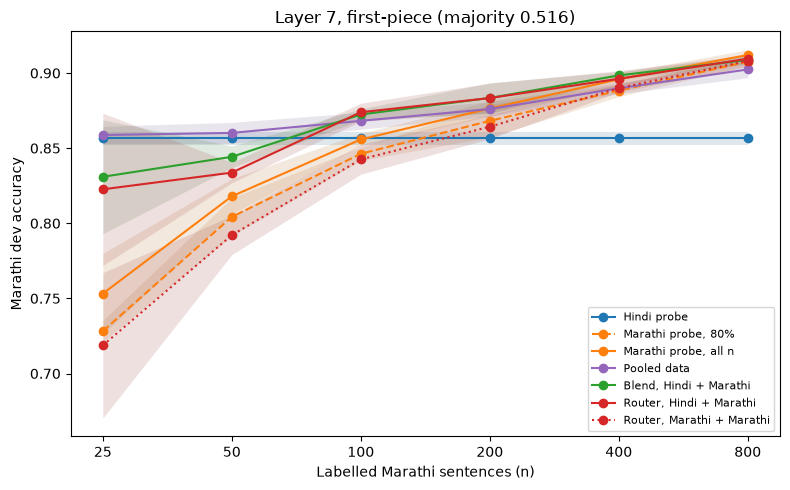

In [4]:
methods = {
    "hindi": "Hindi probe",
    "marathi_80": "Marathi probe, 80%",
    "marathi_100": "Marathi probe, all n",
    "pooled": "Pooled data",
    "blend_hm": "Blend, Hindi + Marathi",
    "router_hm": "Router, Hindi + Marathi",
    "blend_mm": "Blend, Marathi + Marathi",
    "router_mm": "Router, Marathi + Marathi",
    "other_share_hm": "Hindi share of blend",
    "other_share_mm": "2nd Marathi share of blend",
}
sizes = CONFIG["marathi_train_sentences"]
summary = {key: {n: {"mean": np.mean([r[key] for r in runs if r["n"] == n]),
                     "std": np.std([r[key] for r in runs if r["n"] == n])} for n in sizes}
           for key in methods}
result = {"layer": LAYER, "pooling": POOLING, "split": "mr dev", "majority": majority,
          "summary": summary, "runs": runs}
(ROOT / "results" / "combination.json").write_text(json.dumps(result, indent=2) + "\n")

print(f"{'n':28s}" + "".join(f"{n:>15d}" for n in sizes))
for key, label in methods.items():
    print(f"{label:28s}" + "".join(f"{summary[key][n]['mean']:9.3f} ±{summary[key][n]['std']:.3f}" for n in sizes))
print("\nC chosen by each probe, per seed:")
for name in ["hindi", "marathi_80", "marathi_100", "pooled"]:
    print(f"  {name}:", {n: [r[f"C_{name}"] for r in runs if r["n"] == n] for n in sizes})
print("\nRouter penalty chosen (None = fell back to the blend):")
for name in ["hm", "mm"]:
    print(f"  {name}:", {n: [r[f"penalty_{name}"] for r in runs if r["n"] == n] for n in sizes})

figure, ax = plt.subplots(figsize=(8, 5))
lines = [("hindi", "C0", "-"), ("marathi_80", "C1", "--"), ("marathi_100", "C1", "-"),
         ("pooled", "C4", "-"), ("blend_hm", "C2", "-"), ("router_hm", "C3", "-"), ("router_mm", "C3", ":")]
for key, color, style in lines:
    mean = np.array([summary[key][n]["mean"] for n in sizes])
    std = np.array([summary[key][n]["std"] for n in sizes])
    # The band is the line's colour mixed half-way with grey.
    band = 0.5 * np.array(to_rgb(color)) + 0.5 * np.array(to_rgb("grey"))
    ax.fill_between(sizes, mean - std, mean + std, color=band, alpha=0.18, linewidth=0)
    ax.plot(sizes, mean, color=color, linestyle=style, marker="o", label=methods[key])
ax.set(xscale="log", xticks=sizes, xticklabels=sizes, xlabel="Labelled Marathi sentences (n)",
       ylabel="Marathi dev accuracy", title=f"Layer {LAYER}, {POOLING}-piece (majority {majority:.3f})")
ax.minorticks_off()
ax.legend(fontsize=8)
figure.tight_layout()
figure.savefig(ROOT / "results" / "combination.png", dpi=150)
plt.show()

## Are the differences real?

Compares pairs of methods on the same Marathi dev nouns. Nouns in one sentence
are not independent, so the sentence is the unit that gets resampled. For each
pair and budget the table shows:

- **difference:** how many points the first method is ahead, averaged over the seeds;
- **95% interval:** from 10,000 bootstrap resamples of the dev sentences;
- **p:** how often randomly swapping the two methods' answers, sentence by sentence,
  gives a difference at least this large;
- **Holm p:** p corrected for running all these comparisons at once;
- **seeds won:** in how many of the five seeds the first method scored higher.

The interval and p only cover which dev sentences we happened to have. How much
the result changes with a different training sample shows in the seeds-won
column and in the ± of the results table.

In [5]:
from statsmodels.stats.multitest import multipletests

comparisons = [
    ("blend_hm", "marathi_100"),   # does the blend beat Marathi alone with the same data?
    ("router_hm", "blend_hm"),     # does choosing per noun add anything?
    ("blend_hm", "pooled"),        # is blending better than pooling the data?
    ("blend_mm", "marathi_100"),   # control: does combining help without Hindi?
]
seeds = [int(seed) for seed in CONFIG["seeds"]]
sentence = np.unique(dev.sentence, return_inverse=True)[1]
nouns_per_sentence = np.bincount(sentence)
rng = np.random.default_rng(0)
draws = rng.integers(0, len(nouns_per_sentence), (10_000, len(nouns_per_sentence)))
flips = rng.choice([-1.0, 1.0], draws.shape)

tests = []
for a, b in comparisons:
    for n in sizes:
        # Per sentence: right answers of a minus those of b, averaged over the seeds.
        diff = np.mean([np.bincount(sentence, correct[seed, n][a] * 1.0 - correct[seed, n][b])
                        for seed in seeds], axis=0)
        observed = diff.sum() / len(sentence)
        boot = diff[draws].sum(1) / nouns_per_sentence[draws].sum(1)
        swapped = (flips * diff).sum(1) / len(sentence)
        tests.append({
            "a": a, "b": b, "n": n, "difference": observed,
            "low": np.percentile(boot, 2.5), "high": np.percentile(boot, 97.5),
            "p": (np.sum(np.abs(swapped) >= abs(observed)) + 1) / (len(swapped) + 1),
            "seeds_won": int(sum(correct[seed, n][a].mean() > correct[seed, n][b].mean() for seed in seeds)),
        })
for test, holm in zip(tests, multipletests([test["p"] for test in tests], method="holm")[1]):
    test["holm_p"] = holm
(ROOT / "results" / "significance.json").write_text(json.dumps(tests, indent=2) + "\n")

print(f"{'comparison':52s}{'n':>5s}{'difference':>12s}{'95% interval':>18s}{'p':>9s}{'Holm p':>9s}{'seeds won':>11s}")
for t in tests:
    print(f"{methods[t['a']] + ' vs ' + methods[t['b']]:52s}{t['n']:5d}{100 * t['difference']:+11.1f} "
          f"  [{100 * t['low']:+5.1f}, {100 * t['high']:+5.1f}]{t['p']:9.4f}{t['holm_p']:9.4f}{t['seeds_won']:8d}/{len(seeds)}")

comparison                                              n  difference      95% interval        p   Holm p  seeds won
Blend, Hindi + Marathi vs Marathi probe, all n         25       +7.8   [ +6.9,  +8.6]   0.0001   0.0024       5/5
Blend, Hindi + Marathi vs Marathi probe, all n         50       +2.6   [ +2.0,  +3.3]   0.0001   0.0024       4/5
Blend, Hindi + Marathi vs Marathi probe, all n        100       +1.7   [ +1.0,  +2.3]   0.0001   0.0024       5/5
Blend, Hindi + Marathi vs Marathi probe, all n        200       +0.7   [ +0.3,  +1.1]   0.0016   0.0144       4/5
Blend, Hindi + Marathi vs Marathi probe, all n        400       +0.3   [ -0.1,  +0.6]   0.1623   0.6491       3/5
Blend, Hindi + Marathi vs Marathi probe, all n        800       -0.3   [ -0.6,  -0.0]   0.0314   0.2198       0/5
Router, Hindi + Marathi vs Blend, Hindi + Marathi      25       -0.8   [ -1.1,  -0.6]   0.0001   0.0024       0/5
Router, Hindi + Marathi vs Blend, Hindi + Marathi      50       -1.1   [ -1.4,  -0.7]

## Controls

Three checks that the results come from what mBERT knows about case, not from
memorising words or from a leak in the setup. Each one reruns the sweep at 25,
100 and 800 Marathi sentences with one thing swapped out:

- **Random word vectors:** every word form gets a fixed random vector in place of
  mBERT's. A probe can then only memorise which forms tend to be Nom or Acc. A
  form spelt the same in Hindi and Marathi gets the same vector.
- **Shuffled labels:** the Hindi and Marathi training labels are shuffled once,
  and every method uses the same shuffled labels; the dev labels stay real.
  Every method should fall to about the majority rate.
- **Control task:** every word form gets a random label, Nom or Acc, in the same
  proportions as the real labels, kept the same wherever the form appears
  (train and dev). It shows how well a probe does by memorising forms alone. The
  gap between the real task and this one (selectivity) is the part that needs
  mBERT's knowledge of case.

In [6]:
CONTROL_SIZES = [25, 100, 800]
rng = np.random.default_rng(0)
forms = sorted(set(hindi.form) | set(marathi.form) | set(dev.form))

vector = dict(zip(forms, rng.normal(size=(len(forms), hindi.x.shape[1])).astype(np.float32)))
control_label = dict(zip(forms, rng.random(len(forms)) < np.concatenate([hindi.y, marathi.y]).mean()))
controls = {
    "random_vectors": [split.replaced(x=np.stack([vector[f] for f in split.form])) for split in (hindi, marathi, dev)],
    "shuffled_labels": [hindi.replaced(y=rng.permutation(hindi.y)), marathi.replaced(y=rng.permutation(marathi.y)), dev],
    "control_task": [split.replaced(y=np.array([control_label[f] for f in split.form])) for split in (hindi, marathi, dev)],
}

control_runs = {"real": [run for run in runs if run["n"] in CONTROL_SIZES]}
control_majority = {"real": majority}
for name, splits in controls.items():
    print(f"--- {name}")
    control_runs[name] = sweep(*splits, CONTROL_SIZES)[0]
    control_majority[name] = max(splits[2].y.mean(), 1 - splits[2].y.mean())

shown = ["hindi", "marathi_100", "pooled", "blend_hm", "router_hm"]
control_summary = {
    name: {key: {n: np.mean([r[key] for r in group if r["n"] == n]) for n in CONTROL_SIZES} for key in shown}
    for name, group in control_runs.items()
}
(ROOT / "results" / "controls.json").write_text(json.dumps(
    {"sizes": CONTROL_SIZES, "majority": control_majority, "summary": control_summary, "runs": control_runs},
    indent=2) + "\n")

print(f"\nMean Marathi dev accuracy over the seeds, for n = {CONTROL_SIZES}")
for name, summary_ in control_summary.items():
    print(f"\n{name} (majority {control_majority[name]:.3f})")
    for key in shown:
        print(f"  {methods[key]:28s}" + "".join(f"{summary_[key][n]:8.3f}" for n in CONTROL_SIZES))
print("\nSelectivity (real task minus control task), in points")
for key in shown:
    print(f"  {methods[key]:28s}" + "".join(
        f"{100 * (control_summary['real'][key][n] - control_summary['control_task'][key][n]):+8.1f}"
        for n in CONTROL_SIZES))

--- random_vectors


/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 13, n  25: marathi_100 0.521, pooled 0.528, blend_hm 0.498, router_hm 0.498


... (218 outputs left out)

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/SSKS/Desktop/MechInterp/project/MI_Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more

seed 89, n 800: marathi_100 0.563, pooled 0.574, blend_hm 0.535, router_hm 0.535



Mean Marathi dev accuracy over the seeds, for n = [25, 100, 800]

real (majority 0.516)
  Hindi probe                    0.856   0.856   0.856
  Marathi probe, all n           0.753   0.856   0.912
  Pooled data                    0.859   0.868   0.902
  Blend, Hindi + Marathi         0.831   0.872   0.909
  Router, Hindi + Marathi        0.823   0.874   0.910

random_vectors (majority 0.516)
  Hindi probe                    0.522   0.522   0.522
  Marathi probe, all n           0.505   0.555   0.618
  Pooled data                    0.522   0.538   0.604
  Blend, Hindi + Marathi         0.494   0.536   0.618
  Router, Hindi + Marathi        0.493   0.537   0.618

shuffled_labels (majority 0.516)
  Hindi probe                    0.479   0.479   0.479
  Marathi probe, all n           0.498   0.499   0.493
  Pooled data                    0.484   0.486   0.481
  Blend, Hindi + Marathi         0.499   0.529   0.517
  Router, Hindi + Marathi        0.500   0.529   0.517

control_task (majo